# Wine Quality (Red & White) — Dataset Overview

We will use the following dataset for this assignment: 

**Source:** UCI Machine Learning Repository  
**Original study:** P. Cortez et al., *Modeling wine preferences by data mining from physicochemical properties*, Decision Support Systems (2009).

## Files
- `winequality-red.csv` —  (Portuguese *Vinho Verde* red wine)
- `winequality-white.csv` — (Portuguese *Vinho Verde* white wine)
- Delimiter: **`;`** (semicolon)

Your solution should be created by __modifying the provided template Jupyter notebook (ML_2526_assessment.ipynb file)__.

Your solution .ipynb file only (do not include the two csv files) should be renamed to __“ML_2526_assessment_xxxx.ipynb”__ where xxxx is your __student number__, compressed in a __zip archive of the same name__ and uploaded to Blackboard under __“Assessment 2 Supporting Documentation upload”__.


# Task 1: Dataset Import & Preprocessing
<font color = red> ***Marks : 6***</font>
1. Please __import the two datasets__ using as a delimitter the __`;`__
2. Add a __`wine type`__ and then __combine the two datasets into a new one__
3. __Compute the size__ for the 1) red, 2) white datasets, and for the combined one.
4. __Compute the missing values per feature__ (if any).
5. __Display the seven (7)__ instances encountered first in the combined dataset.
6. __Display__ the __basic statistics__ of the dataset.

In [ ]:
import pandas as pd

#import both datasets
redWine = pd.read_csv("winequality-red.csv",sep=";")
whiteWine = pd.read_csv("winequality-white.csv",sep=";")

redWine['wine_type'] = 'red'
whiteWine['wine_type'] = 'white'


mixedWine = pd.concat([redWine, whiteWine], ignore_index=True)
#check if any white wines exist
#print("Any white wines:", (mixedWine['wine_type'] == 'white').any())
#print("White wine count:", (mixedWine['wine_type'] == 'white').sum())

#print the sizes of the 3 datasets
print(redWine)
print("red-size: ")#1599
print(len(redWine))
print("white-size: ")#4898
print(len(whiteWine))
print("combined-size: ")#6497
print(len(mixedWine))

RWC = redWine.isnull().sum()#no missing values in red wine check
WWC = whiteWine.isnull().sum()#no missing values in white wine check

print("\n missing red vals: \n")
print(RWC)
print("\n missing white vals: \n")
print(WWC)

""" indexes-
0: fixed acidity
1: volatile acidity
2: citric acid
3: residual sugar
4: chlorides
5: free sulfur dioxide
6: total sulfur dioxide
7: density
8: pH
9: sulphates
10: alcohol
11: quality
"""

#display the first 7 instances encountered in the data set
print(mixedWine[:100])#print first
print(mixedWine.mean(numeric_only=True))#mean for each numerical value
print(mixedWine.median(numeric_only=True))#median value for each collumn
print(mixedWine.mode(numeric_only=True).iloc[0])#mode per column

Range = mixedWine.describe()
mins = Range.loc["min"]
maxs = Range.loc["max"]
ranges = maxs - mins

widest_feature = ranges.idxmax()
widest_value = ranges.max()
narrowest_feature = ranges.idxmin()
narrowest_value = ranges.min()
print("Widest range:")
print(f"{widest_feature}: {widest_value}")

print("\nNarrowest range:")
print(f"{narrowest_feature}: {narrowest_value}")

print(mixedWine.describe())#print basic statistics



# Task 1 (Discussion)
<font color = red> ***Marks : 6***</font>
1. Please __mention the main features measured in the dataset__ (not just mention the column names but try to understand their meaning).
2. Are all the features __numerical__? If not, which ones are __categorical__?
3. Check the __summary statistics__ and mention the features having the __widest__ and the __narrowest range of values__.
4. How many __samples (rows)__ are there for __red__ and __white__ wines __separately__ and __combined__?
5. How many __unique quality classes__ exist in the dataset? Are they __evenly spaced__?
6. Is there any __class imbalance__? Which __quality__ value appears the __most__ and which the __least__?
7. Does the __distribution of quality scores__ differ between __red__ and __white__ wines? Can you explain why this might happen from a __real-world perspective__?

# Task 1D (Answer Cell)
1. it measures 11 properties and a qaulity score and wine type, they represent non volatile acides, the measure of acetic acid levels that cause a vinegary taste,  citric acids that add freshness, residual sugar indicates sweetness post fermentation, chlorides reflect salt content, free and total sulfure dioxide act as ppresevatives, density relates alcohol and sugar mass, ph indicates its acidity, sulphates contribute to antimicrobial properties, and alcohol is the percentage by volume, qaulity is the sensory score from a 3-9 rated by experts and wine type distinguishes between red and white wines.
2.   the numerical features are fixed acidity, volatile acidity, citric acid, residual sugar, chlorides, free sulfur dioxide, total sulfur dioxide, density, pH, sulphates and alcohol. quality and wine type are catagorical(red or white, 3456789). There are no missing values in either data set. the numerical values are typically either float64 or int 64 in the case of qaulity.
3.  the widest range is from the sulfur dioxide with a range of 6 - 289g/l across wines, reflecting higher preservation needs in white wines.  the narrowest range in is density with ranges from 0.99-1.00g/cm^3, other ranges include ( Fixed acidity - 4.6 - 15.9, alcohol 8.4 - 14.9 and ph 1.74 - 4.01)
4. red: 1599 white: 4898 combined: 6497 using len() function
5. there are 7 unique values, (3,4,5,6,7,8,9) evenly spaced by 1 on a consistent ordinal scale from poor to excellent,
6. yes there is a class imabalance with a mode of 6 the qaulity 6 occured the most frequently across both sets, followed by 5. with ultra-high qaulities 9 being the rarest
7. white wines show broader qaulity spread with more high (8-9) and low (3-4) scores, peaking at 6, while reds average more commonly at 5-6 with fewer extremes on either end of the scale, this occurs because whites often use more sulfure dioxide for preservation allowing qaulity variation during production unlike reds which need to age.

# Task 2: Dataset Visualization
<font color = red> ***Marks : 7***</font>
1. __Import__ the libraries you need for __numerical__ and __plotting__ tasks (Please ensure that the combined dataset contains the wine_type and the quality).
2. __Create two separate arrays__: one for __red__ wine __quality scores__ and one for __white__. This is essential to __plot them side by side__ for comparison.
3. __Plot the frequency distribution__ of the target variable (quality type) and __report basic statistics__ such as 1) __minimum__, 2) __maximum__, 3) __mean__, 4) __median__, and 5) __mode__.
4. __Define integer-centered bins__. Use __bin edges__ at __`score-0.5`__ and __`score+0.5`__ to align bars correctly. Also set x-axis tick positions for __clarity__.
5. Then __normalize counts to percentages__ so as to make fair comparisons among the red and wine type.
6. __Precompute a common y-axis scale__ to ensure both subplots use the same maximum y-limit for visual comparability.
7. __Plot__ the two __histograms side by side__.
8. __Annotate__ the bars with their percentage values, __add__ an overall figure title and display the result.

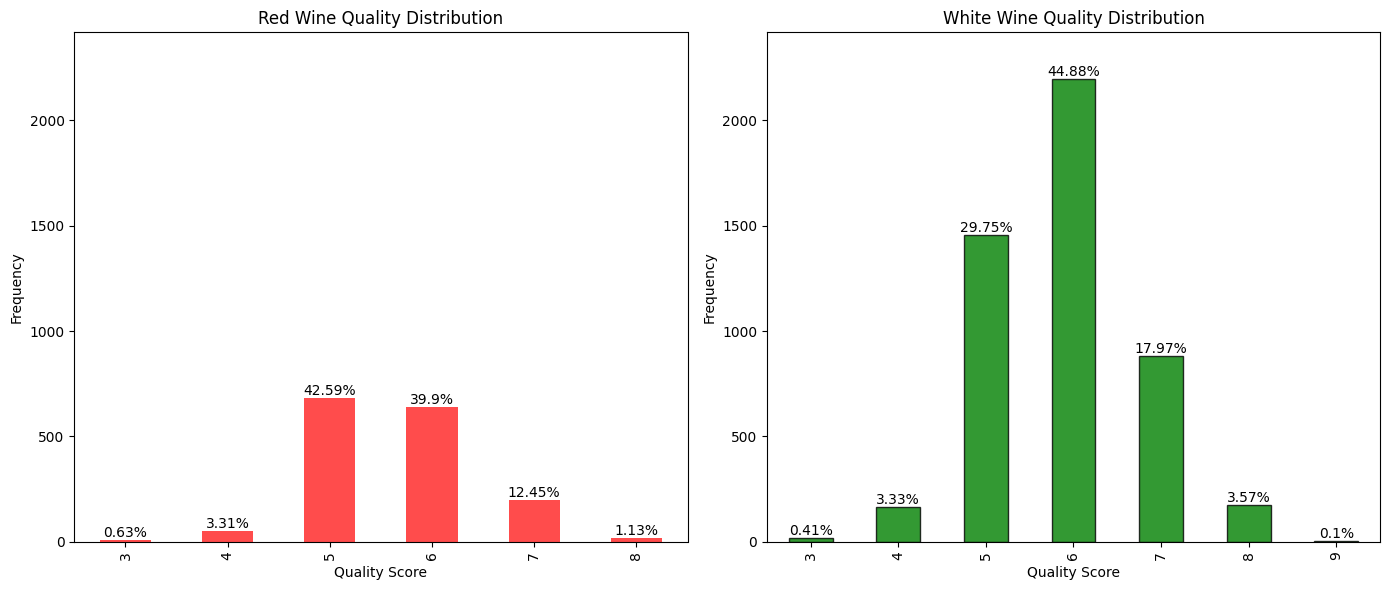

White Minimum: 3
White Maximum: 9
White Mean: 5.87790935075541
White Median: 6.0
White Mode: 6
red Minimum: 3
red Maximum: 8
red Mean: 5.6360225140712945
red Median: 6.0
red Mode: 5
Red wine quality as percent:
 quality
3     0.63
4     3.31
5    42.59
6    39.90
7    12.45
8     1.13
Name: count, dtype: float64
White wine quality as percent:
 quality
3     0.41
4     3.33
5    29.75
6    44.88
7    17.97
8     3.57
9     0.10
Name: count, dtype: float64


In [28]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

#import the datasets and add a winetype
redWine = pd.read_csv("winequality-red.csv",sep=";")
redWine['wine_type'] = 'red'

whiteWine = pd.read_csv("winequality-white.csv",sep=";")
whiteWine['wine_type'] = 'white'

#combine the datasets
mixedWine = pd.concat([redWine, whiteWine], ignore_index=True)

#two arrays to handle the quality values
redWineQuality = redWine["quality"].to_numpy()
whiteWineQuality = whiteWine["quality"].to_numpy()

# Frequency distribution plot
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6))
bins = np.arange(2.5, 10.5, 1)  # Covers quality 3-9
x_pos = np.arange(3, 10)

#set a common y-axis scale to ensure 1:1 comparison
maxRedFreq = redWine['quality'].value_counts().max()
maxWhiteFreq = whiteWine['quality'].value_counts().max()
common_max_freq = max(maxRedFreq, maxWhiteFreq) * 1.1

# Red wine frequency distribution
redBar = redWine['quality'].value_counts().sort_index().plot(kind='bar', ax=ax1, color='red', alpha=0.7)
ax1.set_title('Red Wine Quality Distribution')
ax1.set_xlabel('Quality Score')
ax1.set_ylabel('Frequency')
ax1.set_ylim(0, common_max_freq)

redCount = redWine['quality'].value_counts().sort_index()
red_total = len(redWine)
redPercentages = (redCount / red_total * 100).round(2)

# White wine frequency distribution
whiteBar = whiteWine['quality'].value_counts().sort_index().plot(kind='bar', ax=ax2, color='green', edgecolor='black', alpha=0.8)
ax2.set_title('White Wine Quality Distribution')
ax2.set_xlabel('Quality Score')
ax2.set_ylabel('Frequency')
ax2.set_ylim(0, common_max_freq)

whiteCount = whiteWine['quality'].value_counts().sort_index()
white_total = len(whiteWine)
whitePercentages = (whiteCount / white_total * 100).round(2)

#a function that places a text label of the percentage to 2 nearest decimals
def annotate_bars(ax, bars, percentages):
    for i, bar in enumerate(bars.patches):
        ax.annotate(f'{percentages.iloc[i]}%',
                    (bar.get_x() + bar.get_width()/2, bar.get_height()),
                    ha='center', va='bottom', fontsize=10)


annotate_bars(ax1, redBar, redPercentages)
annotate_bars(ax2, whiteBar, whitePercentages)

plt.tight_layout()
plt.show()

# print Basic statistics
print("White Minimum:", whiteWine['quality'].min())
print("White Maximum:", whiteWine['quality'].max())
print("White Mean:", whiteWine['quality'].mean())
print("White Median:", whiteWine['quality'].median())
print("White Mode:", whiteWine['quality'].mode()[0])
print("red Minimum:", redWine['quality'].min())
print("red Maximum:", redWine['quality'].max())
print("red Mean:", redWine['quality'].mean())
print("red Median:", redWine['quality'].median())
print("red Mode:", redWine['quality'].mode()[0])

print("Red wine quality as percent:\n", redPercentages)
print("White wine quality as percent:\n", whitePercentages)

# Task 2 (Discussion)
<font color = red> ***Marks : 6***</font>
1. Which __quality score(s) dominate__ for red and which for white?
2. Do the distributions suggest __class imbalance overall__ or __within__ each wine type? Please cite approximate percentages from the bars.
3. At which quality scores do red and white wines __differ__ the most in percentage share?
4. Is there a __systematic shift__ (e.g. higher or lower skewness for a specific wine type)? What might explain it?
5. Given the observed class proportions, which __evaluation metrics__ would you __prioritize__ for a classifier (and why)?

# Task 2D (Answer Cell)
1. 5 for red at 42.59% and 6 for white at 44.88%
2. yes there is an imbalance with qualities 5 and 6 being the dominant classes making up roughly 82% (42.59 + 39.90) of the red dataset and 75% (44.88 + 29.75) of the white data set making up roughly 80% across both datasetes with the extreme higher and lower qualities representing the minority classes.
3. at quality 5 the largest difference with reds at 42.59% and whites at 29.75% leaving a gap of 12.84%
4. a systemic shift is present in the quality distributions between the wines. red wine quality shows stronger higher skew towards the peak at score 5 and a longer tail toward higher qualities, white wine shows less skew peaking at 6 with a more even spread across all values. i think this is explained by the fact that red wines take time to age and faces higher expectations for balance and complexity from the tannins/acidity, leading to conservative scoring where white wines benefit from a variance in taste quality and freshness straight after production.
5. The wine quality datasets shows highly imbalanced distributions, with red wine being dominated by qualities 5-6 (82% combined) and extremes like 3 or 8 being under 5%, while white wine also follows a skewed pattern toward mid-range scores 5 and 6 (75% combined).
6. id use F1-score and balance false positives/negatives across the minority classes (such as qualities 3 and 9) to prevent models from trivially predicting the mode 5-6. using AUC-ROC to measure rankings independent of decision thresholds and handle imbalance by avoiding threshold bias (with the majority of classes in 5-6
correct majority guesses dominate the metric despite zero learning)

# Task 3: Implementation
<font color = red> ***Marks : 9***</font>
1. __Create a 4-class label using the rule __`low-quality ≤ 5`__, __`high-quality ≥ 6`__ to define the following classes: __red_low__, __red_high__, __white_low__, __white_high__.
2. Show the value counts and percentages for the four classes.
3. Compute the imbalance ratio as follows: __`max_class_count / min_class_count`__.
4. Define your train/test sets and show per-class counts in each set. Please also verify that all classes are represented in each set.
5. Establish the most appropriate evaluation strategy. This should be coded as a function with no return argument as follows: __`def evaluation_strategy():`__

In [ ]:
# Task 3I (Solution Cell)
def evaluation_strategy():
    # Build your evaluation strategy here
    
    print("\nRecommended evaluation strategy:")
evaluation_strategy()

# Task 3 (Discussion)
<font color = red> ***Marks : 7***</font>
1. What kind of __data leakage__ would occur if we kept __quality__ in the __`X`__ set?
2. Did you use __stratification__ during the __train_test_split__? Please __justify__ your choice.
3. What __risks__ might arise in __model evaluation__ if some __folds lack a class__ entirely?
4. __Justify__ the decisions made regarding the __evaluation strategy__. How can you prove that is a) __fair__, b) __reproducible__, c) __free from leakage__, d) __robust to class imbalance__?

# Task 3D (Answer Cell)

# Task 4: Implementation
<font color = red> ***Marks : 10***</font>
1. __Set up__ a __logistic regression__ classifier.
2. Use the __`evaluation_strategy()`__ function to __report__ your results

In [ ]:
# Task 4I (Solution Cell)

# Task 4 (Discussion)
<font color = red> ***Marks : 7***</font>
1. __Discuss__ the results and __justify__ the <font color = green> __pros__ </font> and <font color = red> __cons__ </font> of your methodology
2. __Provide insight__ on how these results can be __improved__.

# Task 4D (Answer Cell)

# Task 5: Implementation
<font color = red> ***Marks : 11***</font>
1. In this task you have to __train__ and __compare three `scikit-learn` classifiers__ on the __4-class dataset__ previously created.
2. All three classifiers should allow __hyperparameter tuning__.
3. To do so, it is __strongly suggested__ to use a __train/validation/test__ workflow.
4. You are __strongly advised__ <font color = red> __not to use__ a __random forest__ classifier.

In [ ]:
# Task 5I (Solution Cell)

# Task 5 (Discussion)
<font color = red> ***Marks : 9***</font>
1. __Justify__ your choices regarding the __three different__ classifiers.
2. Report __which classifier performed better__, and which had the __poorest performance__. How can you __explain__ their performance?
3. Report the __optimal parameter set__ for each classifier, their __meaning__, and try to __explain__ this result.
4. Given your results, if you could __keep only one__ classifier, which would you choose for <font color = blue> __deployment__ </font> and __why__? Please __justify__ your answer by referring to __interpretability__, __performance__, __stability__, __computational cost__, and __resilience to class imbalance__.
5. Imagine you are presenting your work to a __non-technical stakeholder__: How would you explain why __tuning matters__ and __show evidence__ that it __improved performance__?

# Task 5D (Answer Cell)

# Task 6 (Implementation)
<font color = red> ***Marks : 12***</font>
1. __Build one ensemble classifier__ that <font color = blue> __stacks your three tuned non-ensemble__ </font> models from the previous task.
2. To do so, please use __`scikit-learn`__’s <font color = blue> __StackingClassifier__ </font>.
3. To do so, it is strongly suggested to use a __train/validation/test__ workflow.
4. There is a strong suggestion to use a __Train/Validation/Test__ protocol (no CV for selection here) and __tune key hyperparameters__ on the __Validation__ split and show whether __staking improves your evaluation strategy__ over the best single model.

In [ ]:
# Task 6I (Solution Cell)

# Task 6 (Discussion)
<font color = red> ***Marks : 10***</font>
1. Did the __ensemble outperform__ your __best single__ model or not? __Justify__ your answer by considering __model diversity__, __overfitting__ and __data size__.
2. Why __combining several diverse base__ classifiers may produce __better generalization__ than any __single__ model?
3. How do __ensemble methods__ like __stacking__ reduce __variance__, __bias__ or __both__?
4. Why is __model diversity__ important in ensembles? What would happen if __all base models made similar mistakes__?
5. How can using a __meta-learner__ in __stacking__ <font color = red> __improve the strengths__ </font> of each base model?

# Task 6D (Answer Cell)